# TP2 ► Data Preparation and Train / Validation / Test Split Dataset analysis, stratified split and reproducibility

# 1. TP Objectives

This TP is a guided TP: the student follows the steps in order, executes the code cells and progressively observes how to build a reliable experimental protocol. The dataset used is a raw image dataset, without prior separation into Train, Validation and Test sets.

The objective is therefore to build this separation ourselves by following good machine learning practices. At the end of the TP, the student will be able to:

- load an image dataset organized by classes;
- build a table describing all the images;
- analyze statistics and class distribution;
- visualize representative examples;
- build a stratified Train / Validation / Test split;
- verify the absence of overlap between sets;
- make the split reproducible using a fixed seed;
- save the split so that it can be reused in the following TPs.

The main result of the TP is a reference file containing the membership of each image in one of the three sets.

# 2. Context

## 2.1 Why use a raw dataset?

In a pattern recognition experiment, it is important to control the data separation ourselves. A dataset already split into Train and Test does not always allow us to build the desired experimental protocol, especially when we want to have a Validation set.

In this TP, we therefore use the Flowers Recognition dataset, organized as directories, with one directory corresponding to each class.

The dataset contains five flower categories:

- Daisy;
- Dandelion;
- Rose;
- Sunflower;
- Tulip.

The images are initially grouped by class but are not separated into Train, Validation and Test. The separation will therefore be performed within this TP. Important: the separation between the Train, Validation and Test sets will be performed in this TP. Students must therefore not perform any manual separation before running the notebook. The dataset is available on Kaggle at: https://www.kaggle.com/datasets/alxmamaev/flowers-recognition

## 2.2 Automatic download with KaggleHub

To make the TP reproducible, the dataset will be downloaded directly from Kaggle using the Python library kagglehub. This approach avoids manually downloading and extracting the file from the Kaggle web interface. At the end of this step, the dataset must be available locally in the Python environment and its flowers/ folder must be identifiable automatically.

In [1]:
import kagglehub
from pathlib import Path

/home/asura/projects/asura-mlkit/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATASET_ID = "alxmamaev/flowers-recognition"

DOWNLOAD_DIR = Path("../datasets/raw/")
dataset_path = kagglehub.dataset_download(
    DATASET_ID,
    output_dir=str(DOWNLOAD_DIR)
)

print("Dataset downloaded to: ", dataset_path)

Dataset downloaded to:  ../datasets/raw


**Do not manually modify the contents of the `flowers/` folder.**

## 2.3 Dataset organization

After download and extraction, the data is organized as follows:

```
data/
└── flowers/
    ├── daisy/
    ├── dandelion/
    ├── rose/
    ├── sunflower/
    └── tulip/
```

> Do not manually modify the contents of the `flowers` folder.

## 2.4 Role of the three sets

| Set | Allowed use | Forbidden use |
|---|---|---|
| **Train** | Learn the model parameters and fit the learned transformations | Directly use Test information for learning |
| **Validation** | Choose hyperparameters, compare models, perform early stopping | Be used as final training data without control |
| **Test** | Final evaluation of the model once the choices are made | Be used to choose hyperparameters or the model |

## 2.5 Data leakage

Data leakage occurs when information from the Validation or Test set indirectly influences the learning or the design of the model. We specifically want to avoid:

- the same image being present in two sets;
- the Test set being used to choose a model;
- a learned preprocessing being computed on all images;
- the split changing between two experiments.

Fundamental rule for the following TPs:

**Split → Preprocessing learned on Train → Training → Validation → Final Test**

For example, in TP3: a scaler is fitted only on Train; a BoVW vocabulary for SURF is learned only on Train; Validation and Test features are transformed with the parameters learned on Train.

## 2.6 General pipeline

Flowers Recognition (raw dataset) → Directory traversal and DataFrame construction → Statistics + class distribution → Image visualization → Stratified split 70/15/15 (seed = 42) → Train / Validation / Test → Split saving → TP3 (Hu + LBP + HOG + SURF + MLP)

## Step 1: Environment preparation

Create the working environment and define the constants used throughout the TP.

In [3]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split

In [4]:
SEED = 42

DATA_DIR = Path("../datasets/raw/flowers/")
SPLIT_DIR = Path("../datasets/split/flowers/")

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
CLASS_NAMES = [
    "daisy",
    "dandelion",
    "rose",
    "sunflower",
    "tulip"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff"
}

print("Dataset :", DATA_DIR)
print("Classes :", CLASS_NAMES)
print("Seed    :", SEED)

Dataset : ../datasets/raw/flowers
Classes : ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Seed    : 42


## Step 2: Dataset traversal

Build a table containing one row per image.

| Column | Meaning |
|---|---|
| `filepath` | Path to the image |
| `filename` | File name |
| `class_name` | Class name |
| `label` | Class number |

In [6]:
records = []

for label, class_name in enumerate(CLASS_NAMES):

    class_dir = DATA_DIR / class_name

    for path in class_dir.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        records.append({
            "filepath": str(path),
            "filename": path.name,
            "class_name": class_name,
            "label": label
        })


df = pd.DataFrame(records)

print("Total number of images :", len(df))
print(df.head())

Total number of images : 4319
                                            filepath  \
0  ../datasets/raw/flowers/daisy/5087720485_c0914...   
1  ../datasets/raw/flowers/daisy/1392131677_116ec...   
2  ../datasets/raw/flowers/daisy/6089825811_80f25...   
3  ../datasets/raw/flowers/daisy/8932490012_cc08e...   
4  ../datasets/raw/flowers/daisy/3750771898_cfd50...   

                      filename class_name  label  
0    5087720485_c0914fb623.jpg      daisy      0  
1    1392131677_116ec04751.jpg      daisy      0  
2    6089825811_80f253fbe1.jpg      daisy      0  
3  8932490012_cc08e690ba_n.jpg      daisy      0  
4  3750771898_cfd50090ba_n.jpg      daisy      0  


## Step 3: Statistical analysis of the dataset

### 3.1 Number of images per class

In [7]:
counts = (
    df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES)
)

print(counts)

print("\nTotal :", counts.sum())

class_name
daisy         765
dandelion    1052
rose          784
sunflower     734
tulip         984
Name: count, dtype: int64

Total : 4319


Compute the proportions:

In [8]:
proportions = 100 * counts / counts.sum()

stats_classes = pd.DataFrame({
    "count": counts,
    "proportion_percent": proportions
})

print(stats_classes)

            count  proportion_percent
class_name                           
daisy         765           17.712433
dandelion    1052           24.357490
rose          784           18.152350
sunflower     734           16.994675
tulip         984           22.783052


### 3.2 Distribution visualization

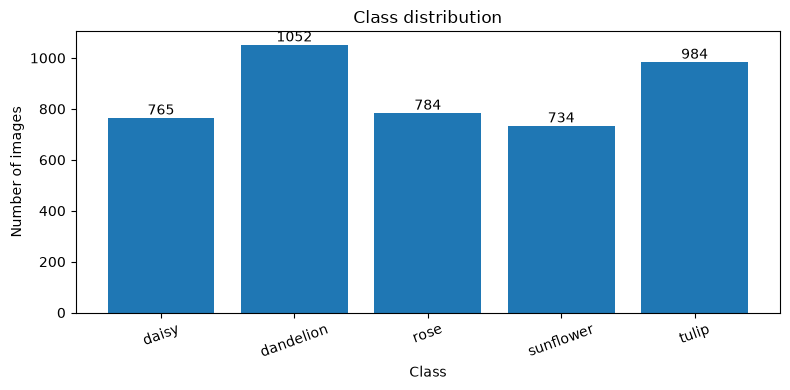

In [9]:
plt.figure(figsize=(8, 4))

bars = plt.bar(
    stats_classes.index,
    stats_classes["count"]
)

plt.bar_label(bars)

plt.xlabel("Class")
plt.ylabel("Number of images")
plt.title("Class distribution")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### 3.3 Imbalance measure

Ratio between the most represented class and the least represented class:

$$R = \frac{N_{max}}{N_{min}}$$

| Ratio | Interpretation |
|---|---|
| R ≈ 1 | Relatively balanced classes |
| 1 < R < 2 | Moderate imbalance |
| R ≥ 2 | Significant imbalance to be taken into account in the evaluation |

In [10]:
ratio = counts.max() / counts.min()

print("Majority class :", counts.idxmax())
print("Minority class :", counts.idxmin())
print("Max/min ratio  :", round(ratio, 3))

Majority class : dandelion
Minority class : sunflower
Max/min ratio  : 1.433


> Imbalance does not automatically mean that the data must be oversampled. The first objective is to preserve the class distribution during the split.

## Step 4: Image visualization

Observe the different classes and visually verify the quality of the dataset.

### 4.1 One sample per class

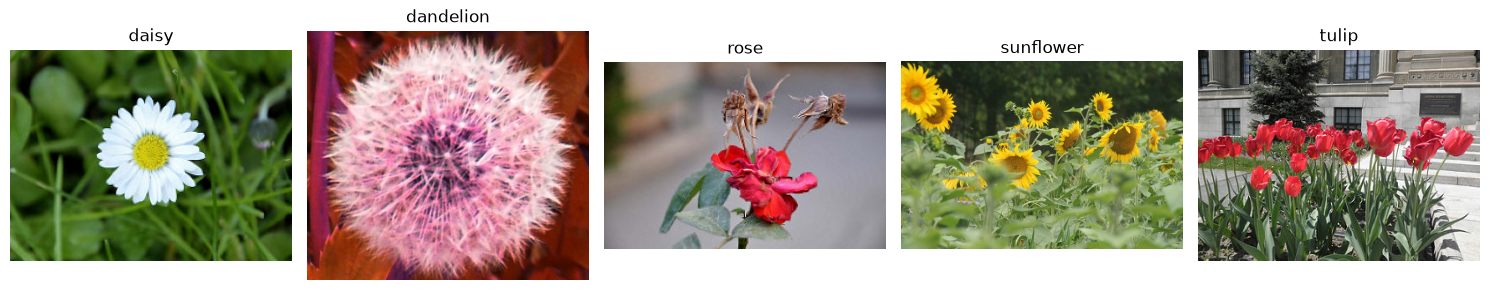

In [11]:
fig, axes = plt.subplots(
    1, len(CLASS_NAMES),
    figsize=(15, 4)
)

for ax, class_name in zip(axes, CLASS_NAMES):

    subset = df[df["class_name"] == class_name]

    row = subset.sample(
        n=1,
        random_state=SEED
    ).iloc[0]

    with Image.open(row["filepath"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 4.2 Grid of samples

Display several images from each class:

In [ ]:
n_samples = 5

fig, axes = plt.subplots(
    len(CLASS_NAMES),
    n_samples,
    figsize=(12, 12)
)

for i, class_name in enumerate(CLASS_NAMES):

    subset = df[df["class_name"] == class_name]

    samples = subset.sample(
        n=min(n_samples, len(subset)),
        random_state=SEED
    )

    for j, (_, row) in enumerate(samples.iterrows()):

        with Image.open(row["filepath"]) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].axis("off")

        if j == 0:
            axes[i, j].set_title(
                class_name,
                loc="left"
            )

plt.tight_layout()
plt.show()

**To observe:**
- variation in appearance within the same class;
- variation in size and orientation of the flowers;
- texture differences;
- different backgrounds;
- possible atypical images.

These variations explain why a simple descriptor may not be sufficient to obtain good classification.

## Step 5: Creating the stratified split

Build three sets (Train, Validation, Test) while preserving the class proportions: **70% Train / 15% Validation / 15% Test**.

The split is performed in two steps:
1. Dataset → 70% Train + 30% Remaining
2. 30% Remaining → 15% Validation + 15% Test

In [12]:
train_df, rest_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    rest_df,
    test_size=0.50,
    random_state=SEED,
    stratify=rest_df["label"]
)

print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))

Train      : 3023
Validation : 648
Test       : 648


The `stratify` argument is essential. Without it, class proportions may differ between Train, Validation and Test. With it, the split approximately preserves the original class distribution.

## Step 6: Verification of the distribution

Verify that the three sets have a similar class distribution. First, the contingency table:

In [13]:
split_df = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test")
], ignore_index=True)

split_df = split_df[
    [
        "split",
        "filepath",
        "filename",
        "class_name",
        "label"
    ]
]

print(
    pd.crosstab(
        split_df["split"],
        split_df["class_name"]
    )
)

class_name  daisy  dandelion  rose  sunflower  tulip
split                                               
test          115        158   118        110    147
train         535        736   549        514    689
val           115        158   117        110    148


Proportions:

In [14]:
proportions_split = pd.crosstab(
    split_df["split"],
    split_df["class_name"],
    normalize="index"
)

proportions_split = (
    proportions_split
    .reindex(["train", "val", "test"])
    .reindex(columns=CLASS_NAMES)
)

print(proportions_split.round(4))

class_name   daisy  dandelion    rose  sunflower   tulip
split                                                   
train       0.1770     0.2435  0.1816     0.1700  0.2279
val         0.1775     0.2438  0.1806     0.1698  0.2284
test        0.1775     0.2438  0.1821     0.1698  0.2269


Visualization:

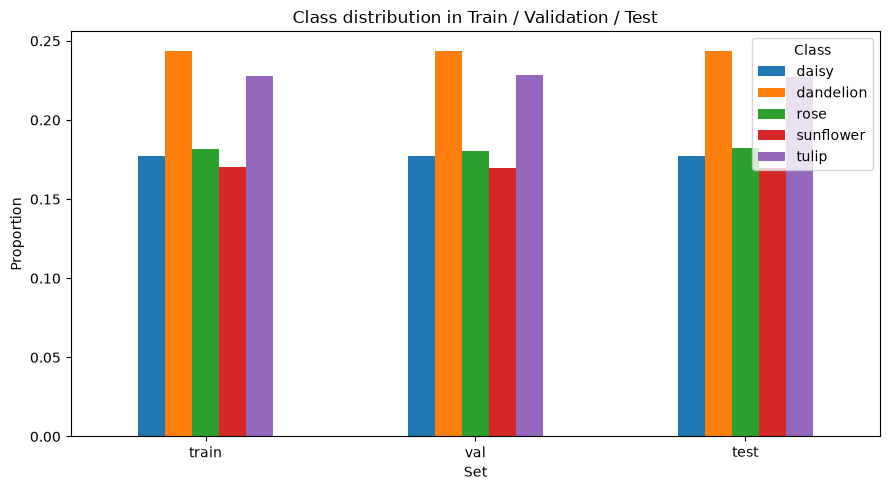

In [15]:
proportions_split.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Proportion")
plt.xlabel("Set")
plt.title("Class distribution in Train / Validation / Test")
plt.xticks(rotation=0)
plt.legend(title="Class")

plt.tight_layout()
plt.show()

## Step 7: Verification of the absence of leakage

*(This step is not detailed in the handout, but its results are required in the deliverables and `verify_split` is used in Step 9, so it is defined here.)*

We check that no image path appears in two sets and that every class is present in every set.

In [16]:
def verify_split(sdf):

    assert set(sdf["split"].unique()) == {"train", "val", "test"}

    path_sets = {
        s: set(sdf.loc[sdf["split"] == s, "filepath"])
        for s in ["train", "val", "test"]
    }

    assert path_sets["train"].isdisjoint(path_sets["val"])
    assert path_sets["train"].isdisjoint(path_sets["test"])
    assert path_sets["val"].isdisjoint(path_sets["test"])

    for split_name in ["train", "val", "test"]:
        classes = set(
            sdf.loc[sdf["split"] == split_name, "class_name"]
        )
        assert classes == set(CLASS_NAMES)

    return True


print("Valid split :", verify_split(split_df))

Valid split : True


Detailed view, to fill in table 13.4:

In [17]:
paths = {s: set(split_df.loc[split_df["split"] == s, "filepath"])
         for s in ["train", "val", "test"]}

print("Common paths Train/Val  :", len(paths["train"] & paths["val"]))
print("Common paths Train/Test :", len(paths["train"] & paths["test"]))
print("Common paths Val/Test   :", len(paths["val"] & paths["test"]))

for s in ["train", "val", "test"]:
    present = set(split_df.loc[split_df["split"] == s, "class_name"])
    print(f"All classes present in {s:5s}:", present == set(CLASS_NAMES))

Common paths Train/Val  : 0
Common paths Train/Test : 0
Common paths Val/Test   : 0
All classes present in train: True
All classes present in val  : True
All classes present in test : True


## Step 8: Saving the split

The final folder will be:

```
data/split/
├── split.csv      <- reference file
├── train.csv
├── val.csv
├── test.csv
└── split_info.json
```

In [18]:
csv_path = SPLIT_DIR / "split.csv"

split_df.to_csv(
    csv_path,
    index=False
)

for split_name in ["train", "val", "test"]:

    subset = split_df[
        split_df["split"] == split_name
    ]

    subset.to_csv(
        SPLIT_DIR / f"{split_name}.csv",
        index=False
    )

print("Split saved to:", SPLIT_DIR)

Split saved to: ../datasets/split/flowers


### 8.1 Saving the experimental information

We also save the parameters used to build the split.

In [19]:
split_info = {

    "seed": SEED,

    "split_ratio": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15
    },

    "classes": CLASS_NAMES,

    "n_images": int(len(df)),

    "n_train": int(
        (split_df["split"] == "train").sum()
    ),

    "n_validation": int(
        (split_df["split"] == "val").sum()
    ),

    "n_test": int(
        (split_df["split"] == "test").sum()
    )
}


with open(
    SPLIT_DIR / "split_info.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        split_info,
        f,
        indent=4,
        ensure_ascii=False
    )


print(
    json.dumps(
        split_info,
        indent=4,
        ensure_ascii=False
    )
)

{
    "seed": 42,
    "split_ratio": {
        "train": 0.7,
        "validation": 0.15,
        "test": 0.15
    },
    "classes": [
        "daisy",
        "dandelion",
        "rose",
        "sunflower",
        "tulip"
    ],
    "n_images": 4319,
    "n_train": 3023,
    "n_validation": 648,
    "n_test": 648
}


## Step 9: Reloading the split

Verify that the data can be reloaded solely from the saved files. In the following TPs, we no longer want to redo the split.

In [20]:
saved_split = pd.read_csv(
    SPLIT_DIR / "split.csv"
)

print(saved_split.head())
print(saved_split.shape)

   split                                           filepath  \
0  train  ../datasets/raw/flowers/dandelion/459748276_69...   
1  train  ../datasets/raw/flowers/dandelion/33980437760_...   
2  train  ../datasets/raw/flowers/dandelion/15819121091_...   
3  train  ../datasets/raw/flowers/dandelion/3584415133_a...   
4  train  ../datasets/raw/flowers/rose/5181899042_0a6ffe...   

                       filename class_name  label  
0    459748276_69101b0cec_n.jpg  dandelion      1  
1  33980437760_60f3ceaf03_n.jpg  dandelion      1  
2  15819121091_26a5243340_n.jpg  dandelion      1  
3     3584415133_a4122ab7b9.jpg  dandelion      1  
4   5181899042_0a6ffe0c8a_n.jpg       rose      2  
(4319, 5)


Verify its integrity:

In [21]:
print(
    "Valid split :",
    verify_split(saved_split)
)

Valid split : True


Reconstruct the three sets:

In [22]:
train_saved = saved_split[
    saved_split["split"] == "train"
].copy()

val_saved = saved_split[
    saved_split["split"] == "val"
].copy()

test_saved = saved_split[
    saved_split["split"] == "test"
].copy()

print("Train      :", len(train_saved))
print("Validation :", len(val_saved))
print("Test       :", len(test_saved))

Train      : 3023
Validation : 648
Test       : 648


## Step 10: Verification of reproducibility

*(Also not detailed in the handout but required in the deliverables.)*

With the same seed and the same dataset, repeating the split must give exactly the same assignment of images to sets.

In [23]:
def make_split_nb(df, seed=SEED):
    tr, rest = train_test_split(
        df, test_size=0.30, random_state=seed, stratify=df["label"]
    )
    va, te = train_test_split(
        rest, test_size=0.50, random_state=seed, stratify=rest["label"]
    )
    return pd.concat([
        tr.assign(split="train"),
        va.assign(split="val"),
        te.assign(split="test")
    ], ignore_index=True)[["split", "filepath", "filename", "class_name", "label"]]


def as_mapping(sdf):
    return sdf.set_index("filepath")["split"].sort_index()


rerun = make_split_nb(df)

print("Same seed, same split      :", as_mapping(rerun).equals(as_mapping(split_df)))
print("Matches the saved split    :", as_mapping(rerun).equals(as_mapping(saved_split)))

other = make_split_nb(df, seed=123)
print("Different seed, same split :", as_mapping(other).equals(as_mapping(split_df)), "(expected: False)")

Same seed, same split      : True
Matches the saved split    : True
Different seed, same split : False (expected: False)


## Step 11: Creating the `data_split.py` module

Transform the work done in the notebook into reusable functions for the next TPs. The cell below writes the file `data_split.py` next to the notebook.

In [24]:
%%writefile data_split.py

from pathlib import Path

import pandas as pd

from sklearn.model_selection import train_test_split


SEED = 42

CLASS_NAMES = [
    "daisy",
    "dandelion",
    "rose",
    "sunflower",
    "tulip"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff"
}


def scan_dataset(data_dir):

    data_dir = Path(data_dir)

    records = []

    for label, class_name in enumerate(CLASS_NAMES):

        class_dir = data_dir / class_name

        for path in class_dir.rglob("*"):

            if not path.is_file():
                continue

            if path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            records.append({
                "filepath": str(path),
                "filename": path.name,
                "class_name": class_name,
                "label": label
            })

    return pd.DataFrame(records)


def make_split(df):

    train_df, rest_df = train_test_split(
        df,
        test_size=0.30,
        random_state=SEED,
        stratify=df["label"]
    )

    val_df, test_df = train_test_split(
        rest_df,
        test_size=0.50,
        random_state=SEED,
        stratify=rest_df["label"]
    )

    split_df = pd.concat(
        [
            train_df.assign(split="train"),
            val_df.assign(split="val"),
            test_df.assign(split="test")
        ],
        ignore_index=True
    )

    return split_df


def verify_split(sdf):

    assert set(
        sdf["split"].unique()
    ) == {
        "train", "val", "test"
    }

    path_sets = {
        s: set(
            sdf.loc[
                sdf["split"] == s,
                "filepath"
            ]
        )
        for s in ["train", "val", "test"]
    }

    assert path_sets["train"].isdisjoint(
        path_sets["val"]
    )

    assert path_sets["train"].isdisjoint(
        path_sets["test"]
    )

    assert path_sets["val"].isdisjoint(
        path_sets["test"]
    )

    for split_name in [
        "train", "val", "test"
    ]:

        classes = set(
            sdf.loc[
                sdf["split"] == split_name,
                "class_name"
            ]
        )

        assert classes == set(CLASS_NAMES)

    return True


def save_split(split_df, output_dir):

    output_dir = Path(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    split_df.to_csv(
        output_dir / "split.csv",
        index=False
    )

    for split_name in [
        "train", "val", "test"
    ]:

        split_df[
            split_df["split"] == split_name
        ].to_csv(
            output_dir /
            f"{split_name}.csv",
            index=False
        )


def load_split(output_dir):

    output_dir = Path(output_dir)

    split_df = pd.read_csv(
        output_dir / "split.csv"
    )

    assert verify_split(split_df)

    return split_df

Writing data_split.py


## Step 12: Testing the module

Verify that the module can be used independently of the notebook.

In [28]:
from data_split import (
    scan_dataset,
    make_split,
    verify_split,
    save_split,
    load_split
)


df_module = scan_dataset(
    str(DATA_DIR)
)

print(
    "Images found :",
    len(df_module)
)


split_module = make_split(
    df_module
)

print(
    "Valid split :",
    verify_split(split_module)
)


save_split(
    split_module,
    str(SPLIT_DIR)
)


split_loaded = load_split(
    str(SPLIT_DIR)
)

print(
    "Reloaded split :",
    len(split_loaded)
)

Images found : 4319
Valid split : True
Reloaded split : 4319


Check that the module gives the same split as the notebook:

In [29]:
print(
    "Module split == notebook split :",
    as_mapping(split_loaded).equals(as_mapping(split_df))
)

Module split == notebook split : True


## Step 13: Results to record

Complete the tables from the results obtained above.

### 13.1 General statistics

| | Value |
|---|---|
| Total number of images | |
| Majority / minority class ratio | |

### 13.2 Class distribution

| Class | Count | Proportion (%) |
|---|---|---|
| Daisy | | |
| Dandelion | | |
| Rose | | |
| Sunflower | | |
| Tulip | | |
| **Total** | | 100 |

### 13.3 Final split

| Set | Number of images | Proportion |
|---|---|---|
| Train | | |
| Validation | | |
| Test | | |
| **Total** | | 100% |

### 13.4 Verifications

| Verification | Result |
|---|---|
| No common path Train/Validation | |
| No common path Train/Test | |
| No common path Validation/Test | |
| All classes present in Train | |
| All classes present in Validation | |
| All classes present in Test | |
| Reproducible split | |

## Step 14: Deliverables

The submitted folder must contain:

```
TP2/
├── tp2.ipynb
├── data_split.py
└── data/
    └── split/
        ├── split.csv
        ├── train.csv
        ├── val.csv
        └── test.csv
```

The notebook must also contain the results of: general statistics, class distribution, image visualization, Train/Validation/Test distribution, verification of the absence of leakage, and verification of reproducibility.